<a href="https://colab.research.google.com/github/Sarah-Manzoor-158/Machine-learning-course/blob/main/puzzle_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Artificial Intelligence Assignemnt Puzzle game

Imports & Puzzle Mechanics

In [1]:
import heapq
import random
import time
from collections import deque
import matplotlib.pyplot as plt

# Goal state defined in the assignment (0 represents the blank space)
GOAL = (1, 2, 3, 8, 0, 4, 7, 6, 5)

# Precompute goal (row, col) coordinates for each tile 1-8 for fast heuristic lookups
GOAL_POS = {tile: (idx // 3, idx % 3) for idx, tile in enumerate(GOAL) if tile != 0}


def print_board(state):
    """Prints a 9-element tuple cleanly as a 3x3 grid."""
    for i in range(0, 9, 3):
        row = [" " if x == 0 else str(x) for x in state[i : i + 3]]
        print(" ".join(row))
    print()


def is_goal(state):
    """Checks if the current board matches the goal configuration."""
    return state == GOAL


def successors(state):
    """Returns a list of (move_name, new_state) for all legal blank slides."""
    blank_idx = state.index(0)
    row, col = blank_idx // 3, blank_idx % 3
    results = []

    # Possible directions: (Move Name, row_change, col_change)
    directions = [("Up", -1, 0), ("Down", 1, 0), ("Left", 0, -1), ("Right", 0, 1)]

    for move_name, dr, dc in directions:
        new_r, new_c = row + dr, col + dc
        if 0 <= new_r < 3 and 0 <= new_c < 3:
            new_idx = new_r * 3 + new_c
            board_list = list(state)
            board_list[blank_idx], board_list[new_idx] = (
                board_list[new_idx],
                board_list[blank_idx],
            )
            results.append((move_name, tuple(board_list)))

    return results


def shuffle(n, seed=None):
    """Creates a guaranteed solvable puzzle by making n random moves from GOAL."""
    rng = random.Random(seed)
    current = GOAL
    prev_state = None

    for _ in range(n):
        valid_moves = successors(current)
        candidates = [s for _, s in valid_moves if s != prev_state]
        prev_state = current
        current = rng.choice(candidates)

    return current


def verify_solution(start, moves):
    """Replays a list of moves from start to confirm it reaches GOAL."""
    current = start
    for move in moves:
        next_states = dict(successors(current))
        if move not in next_states:
            return False
        current = next_states[move]
    return is_goal(current)

print("Cell 1 Ready: Puzzle functions loaded!")

Cell 1 Ready: Puzzle functions loaded!


Uninformed Search Algorithms

In [2]:
def bfs(start):
    """Breadth-First Search using a FIFO queue."""
    start_time = time.perf_counter()
    if is_goal(start):
        return [], 0, time.perf_counter() - start_time

    queue = deque([(start, [])])
    visited = {start}
    nodes_expanded = 0

    while queue:
        state, path = queue.popleft()
        nodes_expanded += 1

        for move, next_state in successors(state):
            if next_state not in visited:
                new_path = path + [move]
                if is_goal(next_state):
                    return new_path, nodes_expanded, time.perf_counter() - start_time
                visited.add(next_state)
                queue.append((next_state, new_path))

    return None, nodes_expanded, time.perf_counter() - start_time


def dfs(start, limit=30):
    """Depth-Limited DFS using a LIFO stack."""
    start_time = time.perf_counter()
    stack = [(start, [])]
    visited_depth = {start: 0}
    nodes_expanded = 0

    while stack:
        state, path = stack.pop()
        if is_goal(state):
            return path, nodes_expanded, time.perf_counter() - start_time

        if len(path) < limit:
            nodes_expanded += 1
            for move, next_state in reversed(successors(state)):
                new_depth = len(path) + 1
                if next_state not in visited_depth or new_depth < visited_depth[next_state]:
                    visited_depth[next_state] = new_depth
                    stack.append((next_state, path + [move]))

    return None, nodes_expanded, time.perf_counter() - start_time


def ucs(start):
    """Uniform Cost Search ordered by path cost g(n)."""
    start_time = time.perf_counter()
    counter = 0
    heap = [(0, counter, start, [])]
    best_g = {start: 0}
    nodes_expanded = 0

    while heap:
        g, _, state, path = heapq.heappop(heap)
        if g > best_g.get(state, float("inf")):
            continue

        if is_goal(state):
            return path, nodes_expanded, time.perf_counter() - start_time

        nodes_expanded += 1
        for move, next_state in successors(state):
            new_g = g + 1
            if new_g < best_g.get(next_state, float("inf")):
                best_g[next_state] = new_g
                counter += 1
                heapq.heappush(heap, (new_g, counter, next_state, path + [move]))

    return None, nodes_expanded, time.perf_counter() - start_time

print("Cell 2 Ready: BFS, DFS, and UCS loaded!")

Cell 2 Ready: BFS, DFS, and UCS loaded!


Heuristics  h1, h2 ,h3

In [3]:
def h_misplaced(state):
    """h1: Counts how many tiles (excluding blank) are not in their goal square."""
    return sum(
        1 for idx, tile in enumerate(state) if tile != 0 and tile != GOAL[idx]
    )


def h_manhattan(state):
    """h2: Sum of Manhattan distances (row diff + col diff) for all tiles."""
    distance = 0
    for idx, tile in enumerate(state):
        if tile != 0:
            curr_r, curr_c = idx // 3, idx % 3
            goal_r, goal_c = GOAL_POS[tile]
            distance += abs(curr_r - goal_r) + abs(curr_c - goal_c)
    return distance


def h_linear_conflict(state):
    """
    Bonus h3: Manhattan distance + 2 for every pair of tiles in the same row or column
    that belong in that row/column, but are reversed relative to their goal order.
    """
    dist = h_manhattan(state)
    conflicts = 0

    # Check row conflicts
    for r in range(3):
        row_tiles = []
        for c in range(3):
            tile = state[r * 3 + c]
            if tile != 0 and GOAL_POS[tile][0] == r:
                row_tiles.append((c, GOAL_POS[tile][1]))
        for i in range(len(row_tiles)):
            for j in range(i + 1, len(row_tiles)):
                if row_tiles[i][1] > row_tiles[j][1]:
                    conflicts += 1

    # Check column conflicts
    for c in range(3):
        col_tiles = []
        for r in range(3):
            tile = state[r * 3 + c]
            if tile != 0 and GOAL_POS[tile][1] == c:
                col_tiles.append((r, GOAL_POS[tile][0]))
        for i in range(len(col_tiles)):
            for j in range(i + 1, len(col_tiles)):
                if col_tiles[i][1] > col_tiles[j][1]:
                    conflicts += 1

    return dist + 2 * conflicts

print("Cell 3 Ready: Heuristics (h1, h2, h3) loaded!")

Cell 3 Ready: Heuristics (h1, h2, h3) loaded!


Informed Search Algorithms — Greedy & A*

In [4]:
def greedy(start, h):
    """Greedy Best-First Search ordered strictly by heuristic h(n)."""
    start_time = time.perf_counter()
    counter = 0
    heap = [(h(start), counter, start, [])]
    visited = {start}
    nodes_expanded = 0

    while heap:
        _, _, state, path = heapq.heappop(heap)
        if is_goal(state):
            return path, nodes_expanded, time.perf_counter() - start_time

        nodes_expanded += 1
        for move, next_state in successors(state):
            if next_state not in visited:
                visited.add(next_state)
                counter += 1
                heapq.heappush(heap, (h(next_state), counter, next_state, path + [move]))

    return None, nodes_expanded, time.perf_counter() - start_time


def astar(start, h):
    """A* Search ordered by f(n) = g(n) + h(n)."""
    start_time = time.perf_counter()
    counter = 0
    heap = [(h(start), counter, 0, start, [])]
    best_g = {start: 0}
    nodes_expanded = 0

    while heap:
        f, _, g, state, path = heapq.heappop(heap)
        if g > best_g.get(state, float("inf")):
            continue

        if is_goal(state):
            return path, nodes_expanded, time.perf_counter() - start_time

        nodes_expanded += 1
        for move, next_state in successors(state):
            new_g = g + 1
            if new_g < best_g.get(next_state, float("inf")):
                best_g[next_state] = new_g
                counter += 1
                new_f = new_g + h(next_state)
                heapq.heappush(heap, (new_f, counter, new_g, next_state, path + [move]))

    return None, nodes_expanded, time.perf_counter() - start_time

print("Cell 4 Ready: Greedy and A* loaded!")

Cell 4 Ready: Greedy and A* loaded!


Sanity Test on 1 Puzzle

In [5]:
sample_puzzle = shuffle(10, seed=1)
print("Sample Puzzle (10 shuffles, seed=1):")
print_board(sample_puzzle)

test_runs = [
    ("BFS", bfs),
    ("DFS", dfs),
    ("UCS", ucs),
    ("Greedy (h2)", lambda s: greedy(s, h_manhattan)),
    ("A* (h1)", lambda s: astar(s, h_misplaced)),
    ("A* (h2)", lambda s: astar(s, h_manhattan)),
    ("A* (h3 Bonus)", lambda s: astar(s, h_linear_conflict)),
]

for name, fn in test_runs:
    moves, expanded, elapsed = fn(sample_puzzle)
    valid = verify_solution(sample_puzzle, moves)
    print(f"{name:<14} -> Moves: {len(moves):<2} | Expanded: {expanded:<5} | Time: {elapsed:.5f}s | Valid: {valid}")

Sample Puzzle (10 shuffles, seed=1):
  2 4
1 3 6
8 7 5

BFS            -> Moves: 10 | Expanded: 382   | Time: 0.00276s | Valid: True
DFS            -> Moves: 30 | Expanded: 33008 | Time: 0.22031s | Valid: True
UCS            -> Moves: 10 | Expanded: 632   | Time: 0.00383s | Valid: True
Greedy (h2)    -> Moves: 18 | Expanded: 182   | Time: 0.00204s | Valid: True
A* (h1)        -> Moves: 10 | Expanded: 42    | Time: 0.00047s | Valid: True
A* (h2)        -> Moves: 10 | Expanded: 23    | Time: 0.00034s | Valid: True
A* (h3 Bonus)  -> Moves: 10 | Expanded: 20    | Time: 0.00079s | Valid: True


Run Full 80-Puzzle Benchmark & Print Tables

In [6]:
shuffle_lengths = [5, 10, 15, 20]
algorithms = [
    ("BFS", lambda s: bfs(s)),
    ("DFS", lambda s: dfs(s, limit=30)),
    ("UCS", lambda s: ucs(s)),
    ("Greedy (h2)", lambda s: greedy(s, h_manhattan)),
    ("A* (h1)", lambda s: astar(s, h_misplaced)),
    ("A* (h2)", lambda s: astar(s, h_manhattan)),
    ("A* (h3 Bonus)", lambda s: astar(s, h_linear_conflict)),
]

avg_nodes = {length: {} for length in shuffle_lengths}
avg_lengths = {length: {} for length in shuffle_lengths}
suboptimal_example = None

for length in shuffle_lengths:
    puzzles = [shuffle(length, seed=length * 100 + i) for i in range(20)]

    for name, algo_fn in algorithms:
        total_nodes = 0
        total_len = 0
        solved_count = 0

        for p in puzzles:
            moves, nodes, _ = algo_fn(p)
            if moves is not None:
                assert verify_solution(p, moves), f"Invalid solution by {name}!"
                total_nodes += nodes
                total_len += len(moves)
                solved_count += 1

                if name == "Greedy (h2)" and suboptimal_example is None:
                    astar_moves, _, _ = astar(p, h_manhattan)
                    if len(moves) > len(astar_moves):
                        suboptimal_example = (p, moves, astar_moves)

        avg_nodes[length][name] = round(total_nodes / solved_count, 1) if solved_count else 0
        avg_lengths[length][name] = round(total_len / solved_count, 2) if solved_count else 0

# Print Tables
headers = ["Shuffle"] + [name for name, _ in algorithms]
print("=== AVERAGE NODES EXPANDED ===")
print(" | ".join(f"{h:<13}" for h in headers))
print("-" * 115)
for length in shuffle_lengths:
    row = [f"{length:<13}"] + [f"{avg_nodes[length][name]:<13}" for name, _ in algorithms]
    print(" | ".join(row))

print("\n=== AVERAGE SOLUTION LENGTH ===")
print(" | ".join(f"{h:<13}" for h in headers))
print("-" * 115)
for length in shuffle_lengths:
    row = [f"{length:<13}"] + [f"{avg_lengths[length][name]:<13}" for name, _ in algorithms]
    print(" | ".join(row))

if suboptimal_example:
    p, g_moves, a_moves = suboptimal_example
    print("\n=== GREEDY SUBOPTIMAL EXAMPLE ===")
    print("Initial State:", p)
    print_board(p)
    print(f"Greedy (h2) Path ({len(g_moves)} moves): {g_moves}")
    print(f"A* (h2) Path ({len(a_moves)} moves):     {a_moves}")

=== AVERAGE NODES EXPANDED ===
Shuffle       | BFS           | DFS           | UCS           | Greedy (h2)   | A* (h1)       | A* (h2)       | A* (h3 Bonus)
-------------------------------------------------------------------------------------------------------------------
5             | 25.9          | 61703.1       | 45.5          | 5.0           | 5.8           | 5.0           | 5.0          
10            | 302.4         | 37834.3       | 490.3         | 44.6          | 36.8          | 15.6          | 14.8         
15            | 2684.5        | 50755.3       | 4273.9        | 184.7         | 253.1         | 50.6          | 32.6         
20            | 20875.9       | 54854.7       | 30141.8       | 318.4         | 2149.4        | 278.2         | 163.3        

=== AVERAGE SOLUTION LENGTH ===
Shuffle       | BFS           | DFS           | UCS           | Greedy (h2)   | A* (h1)       | A* (h2)       | A* (h3 Bonus)
----------------------------------------------------------------

Plot & Save the Comparison Graph

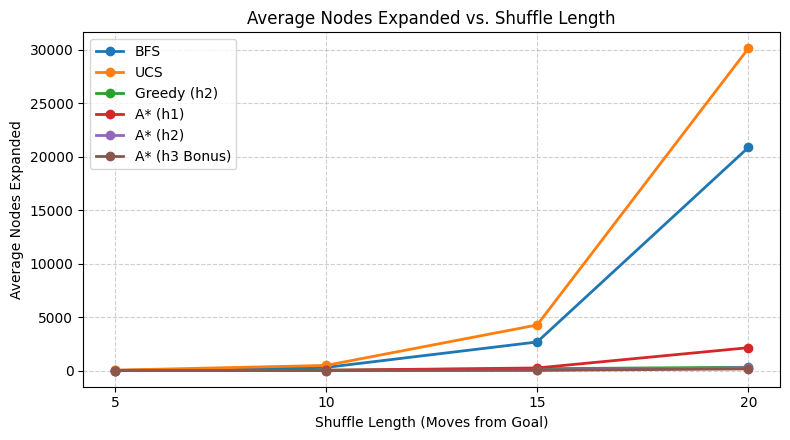

In [7]:
plt.figure(figsize=(8, 4.5))
for name in ["BFS", "UCS", "Greedy (h2)", "A* (h1)", "A* (h2)", "A* (h3 Bonus)"]:
    y_vals = [avg_nodes[l][name] for l in shuffle_lengths]
    plt.plot(shuffle_lengths, y_vals, marker="o", linewidth=2, label=name)

plt.title("Average Nodes Expanded vs. Shuffle Length")
plt.xlabel("Shuffle Length (Moves from Goal)")
plt.ylabel("Average Nodes Expanded")
plt.xticks(shuffle_lengths)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("nodes_expanded_chart.png", dpi=300)
plt.show()